<a href="https://colab.research.google.com/github/sandeep0608/ResNet-18-from-Scratch-on-CIFAR-10/blob/main/ResNet_on_CIFAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


100%|██████████| 170M/170M [26:32<00:00, 107kB/s] 


Training images: 50000
Test images: 10000


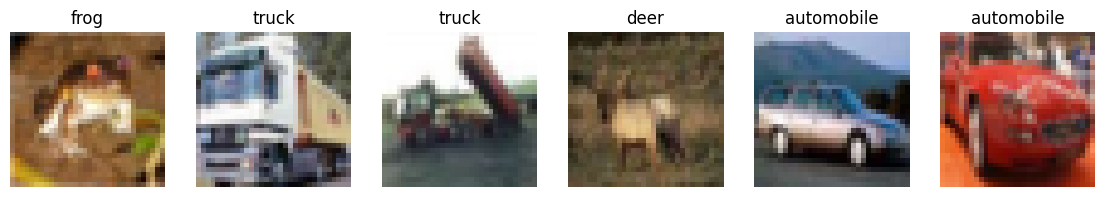

One image's shape: torch.Size([3, 32, 32])


In [2]:
transform = transforms.ToTensor()   # just convert to tensors for now; we'll upgrade this next

train_set = datasets.CIFAR10(root="./data", train=True,  download=True, transform=transform)
test_set  = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

classes = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

print("Training images:", len(train_set))
print("Test images:", len(test_set))

# look at a few
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for i, ax in enumerate(axes):
    image, label = train_set[i]
    ax.imshow(image.permute(1, 2, 0))   # rearrange (channel,H,W) -> (H,W,channel) so it displays
    ax.set_title(classes[label])
    ax.axis("off")
plt.show()

print("One image's shape:", train_set[0][0].shape)

In [3]:
# Training transform: augmentation + normalization
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),       # shift the object around
    transforms.RandomHorizontalFlip(),          # flip left-right
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616)),
])

# Test transform: clean, no augmentation (just convert + normalize)
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616)),
])

train_set = datasets.CIFAR10(root="./data", train=True,  download=True, transform=train_transform)
test_set  = datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)

print("Loaders ready. Train batches:", len(train_loader), "| Test batches:", len(test_loader))

Loaders ready. Train batches: 391 | Test batches: 40


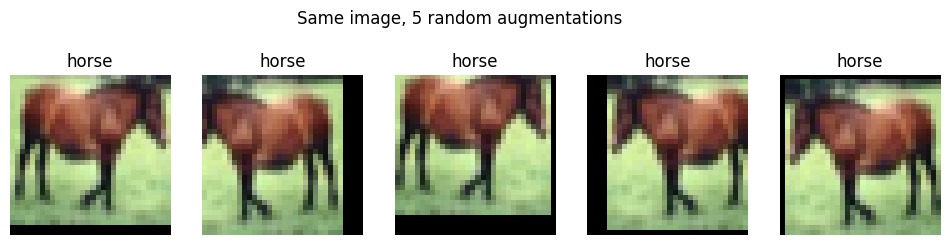

In [4]:
import matplotlib.pyplot as plt

aug_demo = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),                        # no normalize, so it displays naturally
])
demo_set = datasets.CIFAR10(root="./data", train=True, download=True, transform=aug_demo)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax in axes:
    image, label = demo_set[7]                    # same image #7 every time...
    ax.imshow(image.permute(1, 2, 0))             # ...but augmented differently each time
    ax.set_title(classes[label])
    ax.axis("off")
plt.suptitle("Same image, 5 random augmentations")
plt.show()

In [6]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        # The main path = the "edits", F(x):  conv -> BN -> ReLU -> conv -> BN
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)

        # The skip connection (shortcut). Usually it just passes x through unchanged...
        self.shortcut = nn.Sequential()
        # ...but if the block changes shape, we reshape x with a 1x1 conv so it can be added.
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)             # the original input (shape-matched)

        out = F.relu(self.bn1(self.conv1(x)))   # conv -> BN -> ReLU
        out = self.bn2(self.conv2(out))         # conv -> BN   (this is F(x), the "edits")

        # TODO: the skip connection — add the original input back to the edits.
        #   out = out + identity
        out = F.relu(out)                       # final ReLU, after adding
        return out

In [7]:
block = ResidualBlock(3, 16).to(device)        # a block: 3 channels in, 16 out
dummy = torch.randn(1, 3, 32, 32).to(device)   # a fake "image"
print("Input shape: ", dummy.shape)
print("Output shape:", block(dummy).shape)

Input shape:  torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 16, 32, 32])


In [8]:
class ResNet(nn.Module):
    def __init__(self, num_blocks=[2, 2, 2, 2], num_classes=10):
        super().__init__()
        self.in_channels = 64

        # Stem: one conv to expand 3 color channels up to 64, before the blocks
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(64)

        # Four stages of residual blocks (channels grow, image shrinks)
        self.layer1 = self._make_layer(64,  num_blocks[0], stride=1)
        self.layer2 = self._make_layer(128, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(256, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(512, num_blocks[3], stride=2)

        # Head: average each feature map to one number, then decide the class
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc   = nn.Linear(512, num_classes)

    def _make_layer(self, out_channels, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)   # first block may downsample, rest don't
        layers = []
        for s in strides:
            layers.append(ResidualBlock(self.in_channels, out_channels, stride=s))
            self.in_channels = out_channels
        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))   # stem
        out = self.layer1(out)                  # four stages of residual blocks
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.pool(out)                    # global average pool -> 512 x 1 x 1
        out = torch.flatten(out, 1)             # -> a list of 512
        out = self.fc(out)                      # -> 10 class scores
        return out

model = ResNet([2, 2, 2, 2]).to(device)         # this configuration is "ResNet-18"
print(model)
params = sum(p.numel() for p in model.parameters())
print("Total parameters:", params)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layer1): Sequential(
    (0): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, a

In [9]:
images, labels = next(iter(train_loader))
images = images.to(device)
print("Output shape:", model(images).shape)   # expect [128, 10]

Output shape: torch.Size([128, 10])


In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def evaluate():                                  # same idea as LeNet's eval
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            predicted = outputs.argmax(1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

best_acc = 0.0
EPOCHS = 15
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                    # the 5 core lines — same as LeNet
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    test_acc = evaluate()

    if test_acc > best_acc:                       # checkpoint: save the best model so far
        best_acc = test_acc
        torch.save(model.state_dict(), "resnet_cifar_best.pth")

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | loss: {avg_loss:.3f} | test acc: {test_acc:.2f}% | best: {best_acc:.2f}%")

print("Done! Best test accuracy:", round(best_acc, 2), "%")

Epoch  1/15 | loss: 1.746 | test acc: 42.58% | best: 42.58%
Epoch  2/15 | loss: 1.359 | test acc: 39.15% | best: 42.58%
Epoch  3/15 | loss: 1.152 | test acc: 49.71% | best: 49.71%
Epoch  4/15 | loss: 1.008 | test acc: 63.88% | best: 63.88%
Epoch  5/15 | loss: 0.888 | test acc: 67.11% | best: 67.11%
Epoch  6/15 | loss: 0.807 | test acc: 67.09% | best: 67.11%
Epoch  7/15 | loss: 0.726 | test acc: 72.42% | best: 72.42%
Epoch  8/15 | loss: 0.660 | test acc: 70.89% | best: 72.42%
Epoch  9/15 | loss: 0.607 | test acc: 77.44% | best: 77.44%
Epoch 10/15 | loss: 0.562 | test acc: 77.40% | best: 77.44%
Epoch 11/15 | loss: 0.518 | test acc: 79.67% | best: 79.67%
Epoch 12/15 | loss: 0.488 | test acc: 81.41% | best: 81.41%
Epoch 13/15 | loss: 0.453 | test acc: 81.46% | best: 81.46%
Epoch 14/15 | loss: 0.426 | test acc: 84.01% | best: 84.01%
Epoch 15/15 | loss: 0.398 | test acc: 85.75% | best: 85.75%
Done! Best test accuracy: 85.75 %


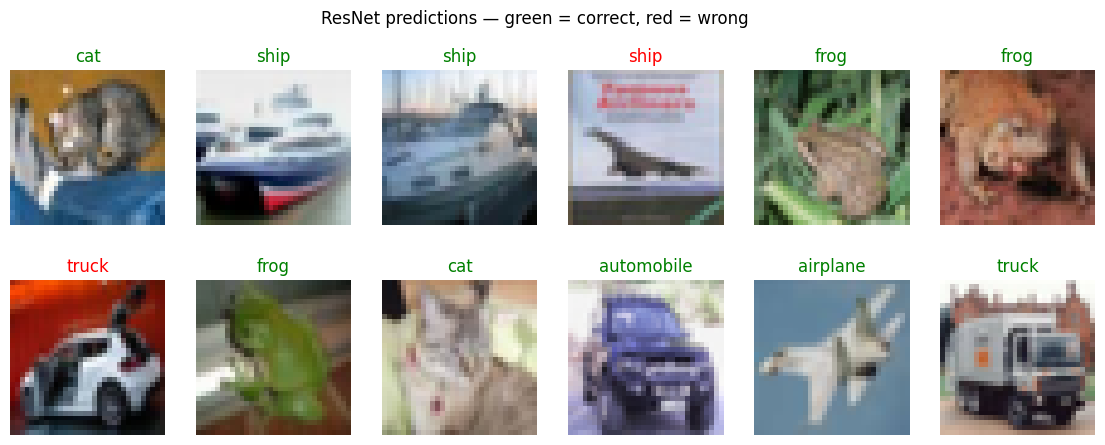

In [12]:
import matplotlib.pyplot as plt

model.load_state_dict(torch.load("resnet_cifar_best.pth"))   # load your best saved model
model.eval()

images, labels = next(iter(test_loader))
with torch.no_grad():
    preds = model(images.to(device)).argmax(1).cpu()

# undo normalization so the images display with natural colors
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    img = images[i] * std + mean
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    right = preds[i].item() == labels[i].item()
    ax.set_title(classes[preds[i]], color=("green" if right else "red"))
    ax.axis("off")
plt.suptitle("ResNet predictions — green = correct, red = wrong")
plt.show()